# 03 · Model Training, Calibration and Threshold Selection

LightGBM candidates are fitted on the training period and compared on the subsequent tuning period.
The selected configuration is refitted on training plus tuning, followed by sigmoid calibration
and review-threshold estimation on a later period. Training artifacts are stored in `artifacts/notebook/full`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src" / "fraud_detection").is_dir()
)
sys.path.insert(0, str(ROOT / "src"))

In [2]:
from dataclasses import replace

from fraud_detection.config import Config
from fraud_detection.data import ID, TARGET, TIME

config = replace(
    Config.load(ROOT / "configs" / "default.yaml"),
    output_dir=str(ROOT / "artifacts" / "notebook" / "full"),
)
processed_dir = Path(config.processed_dir)
working_dir = Path(config.output_dir)
working_dir.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.2})

In [3]:
import gc

import joblib
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression

from fraud_detection.data import validate_transactions
from fraud_detection.features import FeatureBuilder
from fraud_detection.metrics import classification_metrics
from fraud_detection.modeling import FraudModel, log_odds, new_booster
from fraud_detection.pipeline import evaluate_holdout, tune_parameters
from fraud_detection.policy import select_threshold
from fraud_detection.reporting import save_json
from fraud_detection.split import chronological_split

frame = pd.read_parquet(processed_dir / "train.parquet").sort_values([TIME, ID])
frame = frame.reset_index(drop=True)
validate_transactions(frame, labeled=True)
partitions = chronological_split(frame, config)
splits = {}
for name, positions in partitions.items():
    subset = frame.iloc[positions]
    splits[name] = {
        "rows": len(subset),
        "first_day": int(subset[TIME].min() // 86400),
        "last_day": int(subset[TIME].max() // 86400),
        "fraud_rate": float(subset[TARGET].mean()),
    }
del subset
display(pd.DataFrame(splits).T)

,rows,first_day,last_day,fraud_rate
train,356216.0,1.0,101.0,0.033797
tuning,88957.0,102.0,130.0,0.040368
calibration,59937.0,131.0,152.0,0.034019
holdout,85430.0,153.0,182.0,0.035046


In [4]:
%matplotlib inline

## 1. Temporal Hyperparameter Selection

Average precision drives both early stopping and candidate selection.
Each candidate uses feature mappings fitted on the training period.
The selected number of boosting iterations is fixed before refitting; holdout labels play no role in this choice.

,candidate,best_iteration,rows,fraud_count,fraud_rate,average_precision,roc_auc,log_loss,brier_score
0,1,591,88957,3591,0.040368,0.631433,0.908437,0.105437,0.022316
1,0,600,88957,3591,0.040368,0.627360,0.908768,0.098625,0.022261


n_estimators         591.00
learning_rate          0.05
num_leaves            63.00
min_child_samples    150.00
colsample_bytree       0.85
reg_lambda            10.00
Name: selected_parameters, dtype: float64

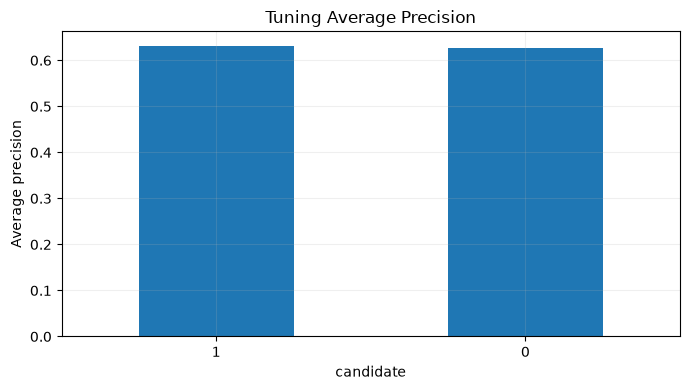

In [5]:
parameters, selection = tune_parameters(frame, partitions, config, working_dir)
candidates = pd.read_csv(working_dir / "candidate_scores.csv")
display(candidates)
display(pd.Series(parameters, name="selected_parameters"))
fig, ax = plt.subplots(figsize=(7, 4))
candidates.plot.bar(x="candidate", y="average_precision", ax=ax, legend=False, rot=0)
ax.set(title="Tuning Average Precision", ylabel="Average precision")
plt.tight_layout()
plt.show()

## 2. Selected-Model Refit

The classifier and feature builder are refitted on the combined training and tuning observations.
Refitting expands the historical evidence available to the model while preserving calibration
and holdout as later periods. The boosting iteration count remains fixed.

In [6]:
fit_rows = np.r_[partitions["train"], partitions["tuning"]]
features = FeatureBuilder()
fit_x = features.fit_transform(frame.iloc[fit_rows])
classifier = new_booster(parameters, config.seed, config.threads)
classifier.fit(fit_x, frame.iloc[fit_rows][TARGET])
del fit_x
gc.collect()

display(
    pd.Series(
        {
            "trees": classifier.n_estimators_,
            "features": classifier.n_features_in_,
            "categorical_columns": len(features.categories_),
        }
    )
)

trees                  591
features               442
categorical_columns     49
dtype: int64

## 3. Sigmoid Probability Calibration

Logistic regression maps raw log-odds to observed fraud labels in the calibration period.
Brier score, log loss and reliability curves characterize probability quality.
A monotonic calibration mapping preserves ranking, so ROC-AUC alone cannot describe its effect.

,rows,fraud_count,fraud_rate,average_precision,roc_auc,log_loss,brier_score
raw,59937.0,2039.0,0.034019,0.621112,0.925776,0.085243,0.019447
calibrated,59937.0,2039.0,0.034019,0.621112,0.925776,0.078409,0.018881


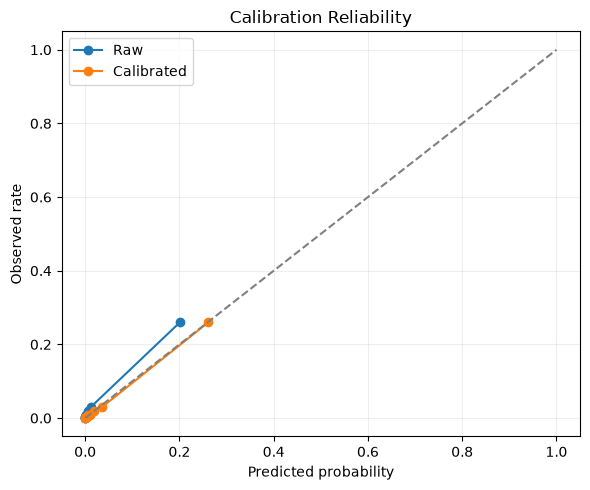

In [7]:
calibration = frame.iloc[partitions["calibration"]]
raw_scores = classifier.predict_proba(features.transform(calibration))[:, 1]
calibrator = LogisticRegression(C=100.0, solver="lbfgs", random_state=config.seed)
calibrator.fit(log_odds(raw_scores), calibration[TARGET])
scores = calibrator.predict_proba(log_odds(raw_scores))[:, 1]
display(
    pd.DataFrame(
        {
            "raw": classification_metrics(calibration[TARGET], raw_scores),
            "calibrated": classification_metrics(calibration[TARGET], scores),
        }
    ).T
)

fig, ax = plt.subplots(figsize=(6, 5))
for values, name in [(raw_scores, "Raw"), (scores, "Calibrated")]:
    observed, predicted = calibration_curve(
        calibration[TARGET],
        values,
        n_bins=10,
        strategy="quantile",
    )
    ax.plot(predicted, observed, marker="o", label=name)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey")
ax.set(
    title="Calibration Reliability",
    xlabel="Predicted probability",
    ylabel="Observed rate",
)
ax.legend()
plt.tight_layout()
plt.show()

## 4. Capacity-Constrained Threshold Selection

Candidate thresholds are evaluated on calibration data under the cumulative daily review quota.
The objective is expected savings under the fixed fraud-loss, review-cost and review-sensitivity assumptions.
Calibration-period results are optimistic because the probability mapping and threshold are both estimated there.

,threshold,reviews,review_rate,fraud_in_review,review_precision,review_recall,expected_prevented_frauds,no_review_cost,expected_cost,expected_savings
0,0.683876,476,0.007942,411,0.863445,0.201569,328.8,203900.0,171496.0,32404.0
1,0.332885,569,0.009493,381,0.669596,0.186856,304.8,203900.0,173989.0,29911.0
2,0.180709,578,0.009643,291,0.503460,0.142717,232.8,203900.0,181198.0,22702.0
3,0.127186,585,0.009760,227,0.388034,0.111329,181.6,203900.0,186325.0,17575.0
4,0.096443,586,0.009777,206,0.351536,0.101030,164.8,203900.0,188006.0,15894.0
5,0.077669,586,0.009777,181,0.308874,0.088769,144.8,203900.0,190006.0,13894.0
6,0.064817,586,0.009777,152,0.259386,0.074546,121.6,203900.0,192326.0,11574.0
7,0.055975,586,0.009777,133,0.226962,0.065228,106.4,203900.0,193846.0,10054.0
8,0.049169,586,0.009777,112,0.191126,0.054929,89.6,203900.0,195526.0,8374.0
9,0.043505,586,0.009777,104,0.177474,0.051005,83.2,203900.0,196166.0,7734.0


locked_threshold     0.683876
review_rate_limit    0.010000
dtype: float64

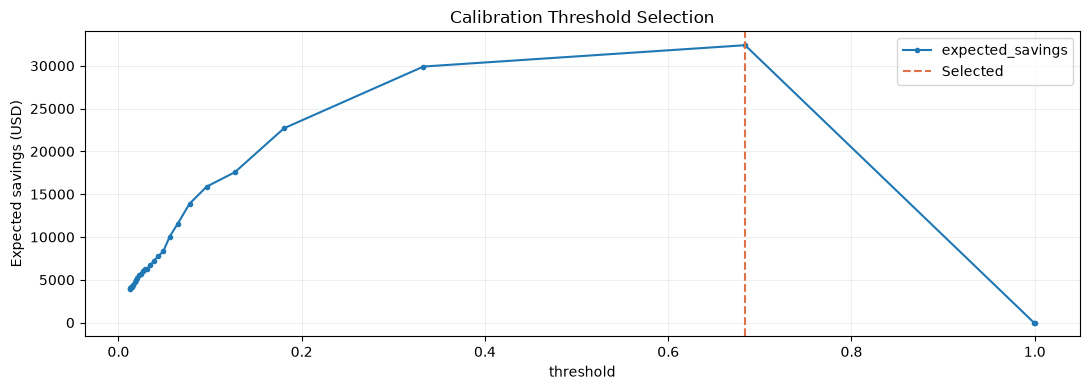

In [8]:
threshold, threshold_search = select_threshold(calibration, scores, config)
display(threshold_search.head(10))
display(pd.Series({"locked_threshold": threshold, "review_rate_limit": config.review_rate}))

fig, ax = plt.subplots()
threshold_search.sort_values("threshold").plot(
    x="threshold",
    y="expected_savings",
    ax=ax,
    legend=False,
    marker=".",
)
ax.axvline(threshold, color="#df7248", linestyle="--", label="Selected")
ax.set(title="Calibration Threshold Selection", ylabel="Expected savings (USD)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Frozen Artifact and Holdout Evaluation

The feature builder, classifier, calibrator and threshold form a single artifact before holdout evaluation.
Prior and logistic baselines provide reference performance.
Final metrics cover ranking, probability quality, review allocation and expected business cost.

In [9]:
artifact = FraudModel(features, classifier, calibrator, threshold, config.review_rate)
joblib.dump(artifact, working_dir / "model.joblib", compress=3)
selection = {
    **selection,
    "parameters": parameters,
    "threshold": threshold,
    "calibration_slope": float(calibrator.coef_[0, 0]),
    "calibration_intercept": float(calibrator.intercept_[0]),
}
save_json(working_dir / "selection.json", selection)
save_json(working_dir / "splits.json", splits)
threshold_search.to_csv(working_dir / "threshold_search.csv", index=False)
importance = pd.DataFrame(
    {
        "feature": classifier.feature_name_,
        "gain": classifier.booster_.feature_importance("gain"),
    }
).sort_values("gain", ascending=False)
importance.to_csv(working_dir / "feature_importance.csv", index=False)
metrics = evaluate_holdout(
    frame,
    partitions,
    artifact,
    scores,
    importance,
    config,
    working_dir,
)
del frame, calibration
gc.collect()

names = ["prior_baseline", "logistic_baseline", "lightgbm_raw", "lightgbm_calibrated"]
display(
    pd.DataFrame({name: metrics[name] for name in names}).T[
        ["rows", "fraud_rate", "average_precision", "roc_auc", "log_loss", "brier_score"]
    ]
)

,rows,fraud_rate,average_precision,roc_auc,log_loss,brier_score
prior_baseline,85430.0,0.035046,0.035046,0.500000,0.151868,0.033818
logistic_baseline,85430.0,0.035046,0.193954,0.760704,0.132081,0.031193
lightgbm_raw,85430.0,0.035046,0.538370,0.896581,0.102554,0.022283
lightgbm_calibrated,85430.0,0.035046,0.538370,0.896581,0.092972,0.021965


## Evaluation Interpretation

Calibration and holdout represent different periods and different statistical roles.
Holdout results describe the frozen pipeline; they do not determine another round of parameter or threshold selection.
Retaining the calibration and holdout exclusions also preserves the meaning of the evaluated probabilities.